# Predicting Property Deed Availability (Çıxarış)

This notebook trains and compares classification models that predict whether a property listing has an official deed (Çıxarış), using listing data such as price, area, floor, rooms, location and renovation status.

## 1. Setup

In [1]:
import os
import time
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn import metrics as sm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, TargetEncoder
from category_encoders import BinaryEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    StackingClassifier,
    VotingClassifier,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 1))
os.makedirs('house_models', exist_ok=True)

## 2. Load the Data

In [2]:
df = pd.read_csv('cleaned_house_sale.csv')

TARGET_COL = 'Çıxarış'
TARGET_LABELS = {0: 'yoxdur', 1: 'var'}
TARGET_MAP = {
    'yoxdur': 0, 'yox': 0, 'no': 0, '0': 0,
    'var': 1, 'yes': 1, '1': 1,
}

df.replace([np.inf, -np.inf], np.nan, inplace=True)

# map the target to 0/1 and drop rows with unknown labels
target_clean = df[TARGET_COL].astype('string').str.strip().str.lower()
df[TARGET_COL] = target_clean.map(TARGET_MAP)
n_missing = df[TARGET_COL].isna().sum()
if n_missing:
    print(f"Dropping {n_missing} rows with unknown target labels")
df.dropna(subset=[TARGET_COL], inplace=True)
df[TARGET_COL] = df[TARGET_COL].astype(int)


def add_house_features(data):
    data = data.copy()
    for col in ['price', 'unit_price', 'lat', 'lng', 'Sahə', 'Mərtəbə', 'Otaq sayı']:
        data[col] = pd.to_numeric(data[col], errors='coerce')

    rooms = data['Otaq sayı'].replace(0, np.nan)
    area = data['Sahə'].replace(0, np.nan)
    floor = data['Mərtəbə'].replace(0, np.nan)

    data['log_price'] = np.log1p(data['price'].clip(lower=0))
    data['log_area'] = np.log1p(data['Sahə'].clip(lower=0))
    data['price_per_room'] = data['price'] / rooms
    data['area_per_room'] = data['Sahə'] / rooms
    data['floor_area_ratio'] = floor / area
    return data


df = add_house_features(df)

print(f"Shape: {df.shape}")
print("\nTarget distribution:")
print(df[TARGET_COL].map(TARGET_LABELS).value_counts(normalize=True).round(3))
display(df.head(3))

Shape: (100762, 19)

Target distribution:
Çıxarış
var       0.79
yoxdur    0.21
Name: proportion, dtype: float64


,price,location,city,products_label,unit_price,shop_name,lat,lng,Kateqoriya,Mərtəbə,Otaq sayı,Sahə,Təmir,Çıxarış,log_price,log_area,price_per_room,area_per_room,floor_area_ratio
0,499999.0,Səbail r.,bakı,Agentlik,3450.000000,Unknown,40.358817,49.824092,Köhnə tikili,7.0,4.0,145.0,var,1,13.122363,4.983607,124999.750000,36.25,0.048276
1,77000.0,Biləcəri q.,bakı,Agentlik,855.555556,Unknown,40.420897,49.807035,Həyət evi/Bağ evi,0.0,4.0,90.0,var,0,11.251574,4.510860,19250.000000,22.50,NaN
2,92000.0,İnşaatçılar m.,bakı,Agentlik,1533.333333,Unknown,40.390293,49.802656,Həyət evi/Bağ evi,0.0,3.0,60.0,var,1,11.429555,4.110874,30666.666667,20.00,NaN


## 3. Features and Train/Test Split

In [3]:
num_feat = [
    'price', 'unit_price', 'lat', 'lng',
    'Sahə', 'Mərtəbə', 'Otaq sayı',
    'log_price', 'log_area', 'price_per_room', 'area_per_room', 'floor_area_ratio',
]
ohe_feat = ['city', 'Kateqoriya']           # low cardinality
bin_feat = ['products_label', 'Təmir']      # medium cardinality
tar_feat = ['location', 'shop_name']        # high cardinality

all_feat = num_feat + ohe_feat + bin_feat + tar_feat
missing = [f for f in all_feat if f not in df.columns]
assert not missing, f"Missing columns: {missing}"

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]}")
print(f"Test size:  {X_test.shape[0]}")

Train size: 80609
Test size:  20153


## 4. Preprocessing

The same preprocessor is used inside every model pipeline, so it is fitted on the training data only.

In [4]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])

ohe_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
])

bin_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', BinaryEncoder()),
])

tar_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', TargetEncoder()),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_feat),
    ('ohe', ohe_pipeline, ohe_feat),
    ('bin', bin_pipeline, bin_feat),
    ('tar', tar_pipeline, tar_feat),
], remainder='drop')

## 5. Evaluation Helper

`evaluate()` fits a pipeline, prints train/test metrics, saves the model and stores the results for the final comparison.

In [5]:
results = {}
POS_LABEL = 1
CLASS_LABELS = [0, 1]
CLASS_NAMES = ['yoxdur', 'var']


def positive_proba(model, X):
    proba = model.predict_proba(X)
    return proba[:, list(model.classes_).index(POS_LABEL)]


def build_metrics(y_train_true, y_train_pred, y_train_proba,
                  y_test_true, y_test_pred, y_test_proba, elapsed):
    train_auc = sm.roc_auc_score(y_train_true, y_train_proba)
    test_auc = sm.roc_auc_score(y_test_true, y_test_proba)
    return {
        'Train BAcc': round(sm.balanced_accuracy_score(y_train_true, y_train_pred), 4),
        'Test BAcc': round(sm.balanced_accuracy_score(y_test_true, y_test_pred), 4),
        'Train AUC': round(train_auc, 4),
        'Test AUC': round(test_auc, 4),
        'Train Gini': round(2 * train_auc - 1, 4),
        'Test Gini': round(2 * test_auc - 1, 4),
        'Train F1': round(sm.f1_score(y_train_true, y_train_pred, zero_division=0), 4),
        'Test F1': round(sm.f1_score(y_test_true, y_test_pred, zero_division=0), 4),
        'Train Prec': round(sm.precision_score(y_train_true, y_train_pred, zero_division=0), 4),
        'Test Prec': round(sm.precision_score(y_test_true, y_test_pred, zero_division=0), 4),
        'Train Rec': round(sm.recall_score(y_train_true, y_train_pred, zero_division=0), 4),
        'Test Rec': round(sm.recall_score(y_test_true, y_test_pred, zero_division=0), 4),
        'Fit Time(s)': round(elapsed, 2),
    }


def print_model_report(name, metrics, y_true, y_pred):
    print('=' * 50)
    print(f"Model: {name}")
    print('=' * 50)
    auc_gap = metrics['Train AUC'] - metrics['Test AUC']
    for k, v in metrics.items():
        note = ''
        if k == 'Test AUC' and auc_gap > 0.10:
            note = '  (possible overfit)'
        elif k == 'Test AUC' and metrics['Train AUC'] < 0.65:
            note = '  (possible underfit)'
        print(f"{k:<12}: {v}{note}")
    print()
    print(sm.classification_report(y_true, y_pred, labels=CLASS_LABELS,
                                   target_names=CLASS_NAMES, zero_division=0))


def model_path(name):
    return f"house_models/{name.replace(' ', '_')}.pkl"


def evaluate(model, name, save=True):
    t0 = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - t0

    metrics = build_metrics(
        y_train, model.predict(X_train), positive_proba(model, X_train),
        y_test, model.predict(X_test), positive_proba(model, X_test),
        elapsed,
    )
    print_model_report(name, metrics, y_test, model.predict(X_test))

    if save:
        joblib.dump(model, model_path(name))
        print(f"Saved to {model_path(name)}")

    results[name] = metrics
    return model

## 6. Models

### Logistic Regression

In [6]:
pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver='lbfgs',
        class_weight='balanced',
        random_state=42,
    ))
])

pipe_lr = evaluate(pipe_lr, 'Logistic Regression')


Model: Logistic Regression
Train BAcc  : 0.7568
Test BAcc   : 0.7544
Train AUC   : 0.8422
Test AUC    : 0.8393
Train Gini  : 0.6844
Test Gini   : 0.6785
Train F1    : 0.8144
Test F1     : 0.8115
Train Prec  : 0.9277
Test Prec   : 0.9271
Train Rec   : 0.7258
Test Rec    : 0.7216
Fit Time(s) : 0.72

              precision    recall  f1-score   support

      yoxdur       0.43      0.79      0.56      4242
         var       0.93      0.72      0.81     15911

    accuracy                           0.74     20153
   macro avg       0.68      0.75      0.68     20153
weighted avg       0.82      0.74      0.76     20153

Saved to house_models/Logistic_Regression.pkl


### Decision Tree

In [7]:
pipe_dt = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42,
    ))
])

pipe_dt = evaluate(pipe_dt, 'Decision Tree')


Model: Decision Tree
Train BAcc  : 0.7653
Test BAcc   : 0.7623
Train AUC   : 0.8525
Test AUC    : 0.846
Train Gini  : 0.705
Test Gini   : 0.692
Train F1    : 0.8347
Test F1     : 0.8321
Train Prec  : 0.9255
Test Prec   : 0.9244
Train Rec   : 0.7601
Test Rec    : 0.7566
Fit Time(s) : 0.44

              precision    recall  f1-score   support

      yoxdur       0.46      0.77      0.57      4242
         var       0.92      0.76      0.83     15911

    accuracy                           0.76     20153
   macro avg       0.69      0.76      0.70     20153
weighted avg       0.83      0.76      0.78     20153

Saved to house_models/Decision_Tree.pkl


### K-Nearest Neighbors

In [8]:
pipe_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=15,
        weights='distance',
        metric='euclidean',
        n_jobs=-1,
    ))
])

pipe_knn = evaluate(pipe_knn, 'KNN')


Model: KNN
Train BAcc  : 0.9937
Test BAcc   : 0.8816
Train AUC   : 0.9999
Test AUC    : 0.9555
Train Gini  : 0.9998
Test Gini   : 0.9109
Train F1    : 0.9978
Test F1     : 0.9571
Train Prec  : 0.9971
Test Prec   : 0.9466
Train Rec   : 0.9985
Test Rec    : 0.9678
Fit Time(s) : 0.16

              precision    recall  f1-score   support

      yoxdur       0.87      0.80      0.83      4242
         var       0.95      0.97      0.96     15911

    accuracy                           0.93     20153
   macro avg       0.91      0.88      0.89     20153
weighted avg       0.93      0.93      0.93     20153

Saved to house_models/KNN.pkl


### Naive Bayes

In [9]:
pipe_nb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

pipe_nb = evaluate(pipe_nb, 'Naive Bayes')


Model: Naive Bayes
Train BAcc  : 0.6821
Test BAcc   : 0.6792
Train AUC   : 0.7901
Test AUC    : 0.7902
Train Gini  : 0.5801
Test Gini   : 0.5804
Train F1    : 0.8607
Test F1     : 0.8583
Train Prec  : 0.8674
Test Prec   : 0.8664
Train Rec   : 0.8542
Test Rec    : 0.8504
Fit Time(s) : 0.21

              precision    recall  f1-score   support

      yoxdur       0.48      0.51      0.49      4242
         var       0.87      0.85      0.86     15911

    accuracy                           0.78     20153
   macro avg       0.67      0.68      0.67     20153
weighted avg       0.78      0.78      0.78     20153

Saved to house_models/Naive_Bayes.pkl


### Random Forest

In [10]:
pipe_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        max_features=0.5,
        min_samples_leaf=2,
        bootstrap=True,
        max_samples=0.8,
        class_weight='balanced',
        criterion='entropy',
        n_jobs=-1,
        random_state=42,
    ))
])

pipe_rf = evaluate(pipe_rf, 'Random Forest')


Model: Random Forest
Train BAcc  : 0.9853
Test BAcc   : 0.9044
Train AUC   : 0.9991
Test AUC    : 0.9666
Train Gini  : 0.9981
Test Gini   : 0.9331
Train F1    : 0.9883
Test F1     : 0.9542
Train Prec  : 0.9977
Test Prec   : 0.9628
Train Rec   : 0.9791
Test Rec    : 0.9458
Fit Time(s) : 6.83

              precision    recall  f1-score   support

      yoxdur       0.81      0.86      0.84      4242
         var       0.96      0.95      0.95     15911

    accuracy                           0.93     20153
   macro avg       0.89      0.90      0.89     20153
weighted avg       0.93      0.93      0.93     20153

Saved to house_models/Random_Forest.pkl


### Extra Trees

In [11]:
pipe_et = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', ExtraTreesClassifier(
        n_estimators=300,
        max_features=0.5,
        min_samples_leaf=2,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42,
    ))
])

pipe_et = evaluate(pipe_et, 'Extra Trees')


Model: Extra Trees
Train BAcc  : 0.9905
Test BAcc   : 0.9019
Train AUC   : 0.9994
Test AUC    : 0.969
Train Gini  : 0.9988
Test Gini   : 0.9381
Train F1    : 0.9932
Test F1     : 0.9603
Train Prec  : 0.998
Test Prec   : 0.9578
Train Rec   : 0.9885
Test Rec    : 0.9629
Fit Time(s) : 2.97

              precision    recall  f1-score   support

      yoxdur       0.86      0.84      0.85      4242
         var       0.96      0.96      0.96     15911

    accuracy                           0.94     20153
   macro avg       0.91      0.90      0.90     20153
weighted avg       0.94      0.94      0.94     20153

Saved to house_models/Extra_Trees.pkl


### Bagging

In [12]:
pipe_bag = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=10, class_weight='balanced'),
        n_estimators=200,
        max_samples=0.8,
        max_features=0.8,
        n_jobs=-1,
        random_state=42,
    ))
])

pipe_bag = evaluate(pipe_bag, 'Bagging')


Model: Bagging
Train BAcc  : 0.8342
Test BAcc   : 0.8176
Train AUC   : 0.916
Test AUC    : 0.8969
Train Gini  : 0.8319
Test Gini   : 0.7937
Train F1    : 0.8796
Test F1     : 0.871
Train Prec  : 0.954
Test Prec   : 0.9464
Train Rec   : 0.8159
Test Rec    : 0.8067
Fit Time(s) : 6.92

              precision    recall  f1-score   support

      yoxdur       0.53      0.83      0.65      4242
         var       0.95      0.81      0.87     15911

    accuracy                           0.81     20153
   macro avg       0.74      0.82      0.76     20153
weighted avg       0.86      0.81      0.82     20153

Saved to house_models/Bagging.pkl


### AdaBoost

In [13]:
pipe_ada = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=200,
        learning_rate=0.1,
        random_state=42,
    ))
])

pipe_ada = evaluate(pipe_ada, 'AdaBoost')


Model: AdaBoost
Train BAcc  : 0.6562
Test BAcc   : 0.6545
Train AUC   : 0.8544
Test AUC    : 0.8491
Train Gini  : 0.7088
Test Gini   : 0.6983
Train F1    : 0.9021
Test F1     : 0.8998
Train Prec  : 0.8473
Test Prec   : 0.8469
Train Rec   : 0.9644
Test Rec    : 0.9597
Fit Time(s) : 23.0

              precision    recall  f1-score   support

      yoxdur       0.70      0.35      0.47      4242
         var       0.85      0.96      0.90     15911

    accuracy                           0.83     20153
   macro avg       0.77      0.65      0.68     20153
weighted avg       0.82      0.83      0.81     20153

Saved to house_models/AdaBoost.pkl


### Gradient Boosting

In [14]:
pipe_gb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        min_samples_leaf=10,
        random_state=42,
    ))
])

pipe_gb = evaluate(pipe_gb, 'Gradient Boosting')


Model: Gradient Boosting
Train BAcc  : 0.711
Test BAcc   : 0.7035
Train AUC   : 0.8843
Test AUC    : 0.8763
Train Gini  : 0.7686
Test Gini   : 0.7526
Train F1    : 0.9146
Test F1     : 0.9095
Train Prec  : 0.8696
Test Prec   : 0.8672
Train Rec   : 0.9645
Test Rec    : 0.9561
Fit Time(s) : 24.1

              precision    recall  f1-score   support

      yoxdur       0.73      0.45      0.56      4242
         var       0.87      0.96      0.91     15911

    accuracy                           0.85     20153
   macro avg       0.80      0.70      0.73     20153
weighted avg       0.84      0.85      0.84     20153

Saved to house_models/Gradient_Boosting.pkl


### HistGradientBoosting

In [15]:
pipe_hgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=400,
        learning_rate=0.05,
        max_depth=6,
        min_samples_leaf=20,
        l2_regularization=1.0,
        class_weight='balanced',
        random_state=42,
    ))
])

pipe_hgb = evaluate(pipe_hgb, 'HistGradientBoosting')


Model: HistGradientBoosting
Train BAcc  : 0.8589
Test BAcc   : 0.8376
Train AUC   : 0.9337
Test AUC    : 0.9138
Train Gini  : 0.8674
Test Gini   : 0.8276
Train F1    : 0.8971
Test F1     : 0.8866
Train Prec  : 0.9627
Test Prec   : 0.9529
Train Rec   : 0.8399
Test Rec    : 0.8289
Fit Time(s) : 3.04

              precision    recall  f1-score   support

      yoxdur       0.57      0.85      0.68      4242
         var       0.95      0.83      0.89     15911

    accuracy                           0.83     20153
   macro avg       0.76      0.84      0.78     20153
weighted avg       0.87      0.83      0.84     20153

Saved to house_models/HistGradientBoosting.pkl


### XGBoost

In [16]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

pipe_xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        scale_pos_weight=scale_pos,
        eval_metric='auc',
        random_state=42,
        verbosity=0,
    ))
])

pipe_xgb = evaluate(pipe_xgb, 'XGBoost')

Model: XGBoost
Train BAcc  : 0.8596
Test BAcc   : 0.8375
Train AUC   : 0.9336
Test AUC    : 0.9149
Train Gini  : 0.8672
Test Gini   : 0.8298
Train F1    : 0.8964
Test F1     : 0.885
Train Prec  : 0.9636
Test Prec   : 0.9536
Train Rec   : 0.838
Test Rec    : 0.8257
Fit Time(s) : 0.72

              precision    recall  f1-score   support

      yoxdur       0.56      0.85      0.68      4242
         var       0.95      0.83      0.89     15911

    accuracy                           0.83     20153
   macro avg       0.76      0.84      0.78     20153
weighted avg       0.87      0.83      0.84     20153

Saved to house_models/XGBoost.pkl


### LightGBM

In [17]:
pipe_lgbm = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        scale_pos_weight=scale_pos,
        n_jobs=-1,
        random_state=42,
        verbose=-1,
    ))
])

pipe_lgbm = evaluate(pipe_lgbm, 'LightGBM')

Model: LightGBM
Train BAcc  : 0.9179
Test BAcc   : 0.8778
Train AUC   : 0.9732
Test AUC    : 0.9433
Train Gini  : 0.9465
Test Gini   : 0.8866
Train F1    : 0.9408
Test F1     : 0.9212
Train Prec  : 0.9802
Test Prec   : 0.963
Train Rec   : 0.9044
Test Rec    : 0.883
Fit Time(s) : 1.34

              precision    recall  f1-score   support

      yoxdur       0.67      0.87      0.76      4242
         var       0.96      0.88      0.92     15911

    accuracy                           0.88     20153
   macro avg       0.81      0.88      0.84     20153
weighted avg       0.90      0.88      0.89     20153

Saved to house_models/LightGBM.pkl


### CatBoost

In [18]:
pipe_cat = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', CatBoostClassifier(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=3,
        scale_pos_weight=scale_pos,
        eval_metric='AUC',
        random_seed=42,
        verbose=0,
    ))
])

pipe_cat = evaluate(pipe_cat, 'CatBoost')

Model: CatBoost
Train BAcc  : 0.8417
Test BAcc   : 0.8296
Train AUC   : 0.9181
Test AUC    : 0.9041
Train Gini  : 0.8363
Test Gini   : 0.8083
Train F1    : 0.8826
Test F1     : 0.8755
Train Prec  : 0.9579
Test Prec   : 0.9528
Train Rec   : 0.8182
Test Rec    : 0.8098
Fit Time(s) : 2.24

              precision    recall  f1-score   support

      yoxdur       0.54      0.85      0.66      4242
         var       0.95      0.81      0.88     15911

    accuracy                           0.82     20153
   macro avg       0.75      0.83      0.77     20153
weighted avg       0.87      0.82      0.83     20153

Saved to house_models/CatBoost.pkl


### MLP Neural Network

In [19]:
pipe_mlp = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu',
        solver='adam',
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
    ))
])

pipe_mlp = evaluate(pipe_mlp, 'MLP Neural Net')


Model: MLP Neural Net
Train BAcc  : 0.8727
Test BAcc   : 0.821
Train AUC   : 0.965
Test AUC    : 0.9222
Train Gini  : 0.9299
Test Gini   : 0.8445
Train F1    : 0.9551
Test F1     : 0.9353
Train Prec  : 0.9422
Test Prec   : 0.9203
Train Rec   : 0.9685
Test Rec    : 0.9507
Fit Time(s) : 23.74

              precision    recall  f1-score   support

      yoxdur       0.79      0.69      0.74      4242
         var       0.92      0.95      0.94     15911

    accuracy                           0.90     20153
   macro avg       0.85      0.82      0.84     20153
weighted avg       0.89      0.90      0.89     20153

Saved to house_models/MLP_Neural_Net.pkl


### Soft Voting (RF + XGBoost + LightGBM)

In [20]:
pipe_vote = VotingClassifier(
    estimators=[('rf', clone(pipe_rf)), ('xgb', clone(pipe_xgb)), ('lgbm', clone(pipe_lgbm))],
    voting='soft',
    n_jobs=-1,
)

pipe_vote = evaluate(pipe_vote, 'Soft Voting')

Model: Soft Voting
Train BAcc  : 0.941
Test BAcc   : 0.8874
Train AUC   : 0.987
Test AUC    : 0.9528
Train Gini  : 0.9741
Test Gini   : 0.9057
Train F1    : 0.9574
Test F1     : 0.9316
Train Prec  : 0.9864
Test Prec   : 0.9639
Train Rec   : 0.9301
Test Rec    : 0.9015
Fit Time(s) : 9.03

              precision    recall  f1-score   support

      yoxdur       0.70      0.87      0.78      4242
         var       0.96      0.90      0.93     15911

    accuracy                           0.90     20153
   macro avg       0.83      0.89      0.86     20153
weighted avg       0.91      0.90      0.90     20153

Saved to house_models/Soft_Voting.pkl


### Stacking

In [21]:
pipe_stack = StackingClassifier(
    estimators=[
        ('rf', clone(pipe_rf)),
        ('hgb', clone(pipe_hgb)),
        ('xgb', clone(pipe_xgb)),
        ('lgbm', clone(pipe_lgbm)),
    ],
    final_estimator=LogisticRegression(max_iter=500, random_state=42),
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1,
)

pipe_stack = evaluate(pipe_stack, 'Stacking')

Model: Stacking
Train BAcc  : 0.9887
Test BAcc   : 0.8959
Train AUC   : 0.9994
Test AUC    : 0.9664
Train Gini  : 0.9988
Test Gini   : 0.9329
Train F1    : 0.994
Test F1     : 0.9613
Train Prec  : 0.9961
Test Prec   : 0.9534
Train Rec   : 0.9919
Test Rec    : 0.9693
Fit Time(s) : 91.73

              precision    recall  f1-score   support

      yoxdur       0.88      0.82      0.85      4242
         var       0.95      0.97      0.96     15911

    accuracy                           0.94     20153
   macro avg       0.92      0.90      0.91     20153
weighted avg       0.94      0.94      0.94     20153

Saved to house_models/Stacking.pkl


## 7. Model Comparison

In [22]:
df_results = pd.DataFrame(results).T
df_results.index.name = 'Model'
df_results = df_results.sort_values('Test AUC', ascending=False)
display(df_results)

print("Best Test AUC: ", df_results['Test AUC'].idxmax())
print("Best Test Gini:", df_results['Test Gini'].idxmax())
print("Best Test BAcc:", df_results['Test BAcc'].idxmax())

,Train BAcc,Test BAcc,Train AUC,Test AUC,Train Gini,Test Gini,Train F1,Test F1,Train Prec,Test Prec,Train Rec,Test Rec,Fit Time(s)
Model,,,,,,,,,,,,,
Extra Trees,0.9905,0.9019,0.9994,0.9690,0.9988,0.9381,0.9932,0.9603,0.9980,0.9578,0.9885,0.9629,2.97
Random Forest,0.9853,0.9044,0.9991,0.9666,0.9981,0.9331,0.9883,0.9542,0.9977,0.9628,0.9791,0.9458,6.83
Stacking,0.9887,0.8959,0.9994,0.9664,0.9988,0.9329,0.9940,0.9613,0.9961,0.9534,0.9919,0.9693,91.73
KNN,0.9937,0.8816,0.9999,0.9555,0.9998,0.9109,0.9978,0.9571,0.9971,0.9466,0.9985,0.9678,0.16
Soft Voting,0.9410,0.8874,0.9870,0.9528,0.9741,0.9057,0.9574,0.9316,0.9864,0.9639,0.9301,0.9015,9.03
LightGBM,0.9179,0.8778,0.9732,0.9433,0.9465,0.8866,0.9408,0.9212,0.9802,0.9630,0.9044,0.8830,1.34
MLP Neural Net,0.8727,0.8210,0.9650,0.9222,0.9299,0.8445,0.9551,0.9353,0.9422,0.9203,0.9685,0.9507,23.74
XGBoost,0.8596,0.8375,0.9336,0.9149,0.8672,0.8298,0.8964,0.8850,0.9636,0.9536,0.8380,0.8257,0.72
HistGradientBoosting,0.8589,0.8376,0.9337,0.9138,0.8674,0.8276,0.8971,0.8866,0.9627,0.9529,0.8399,0.8289,3.04


Best Test AUC:  Extra Trees
Best Test Gini: Extra Trees
Best Test BAcc: Random Forest


### Metric Comparison

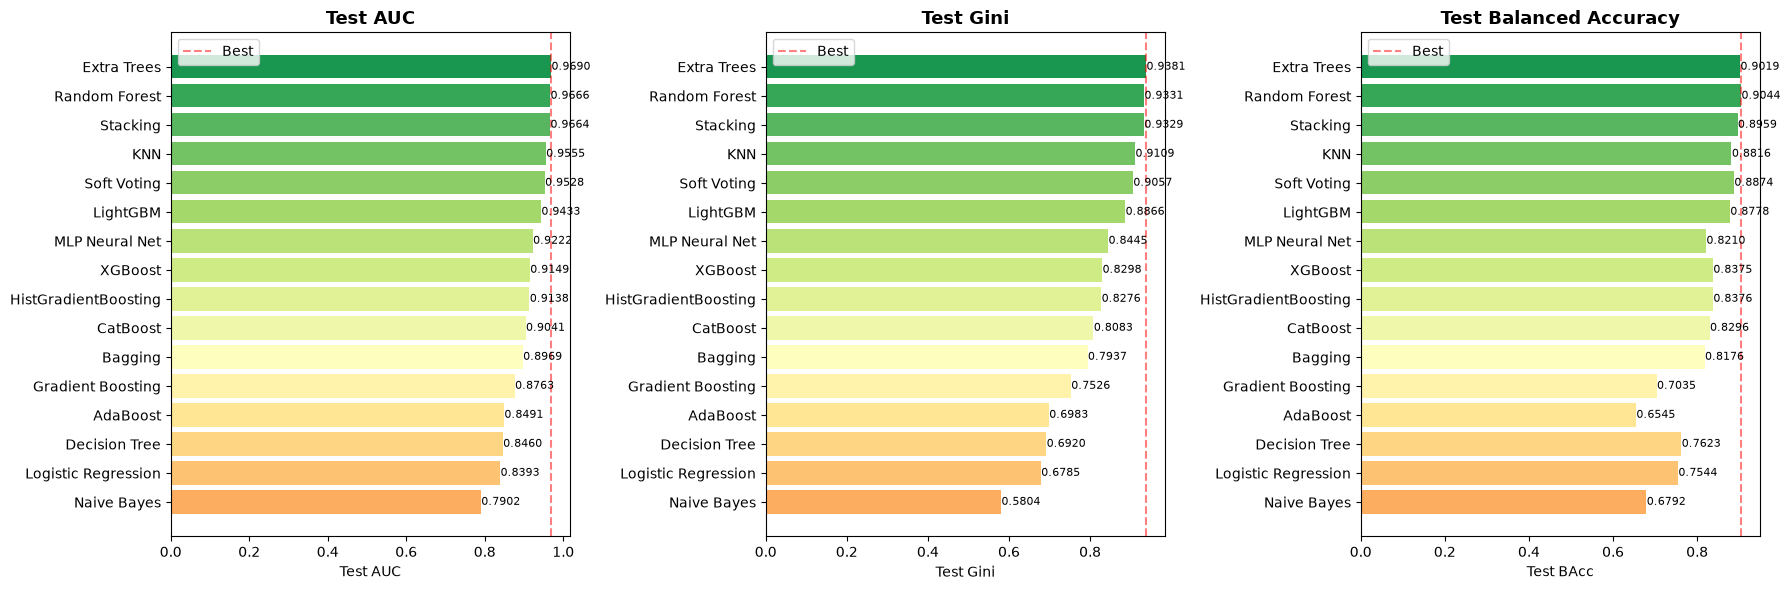

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
df_plot = df_results.sort_values('Test AUC')
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(df_plot)))

for ax, col, title in zip(
    axes,
    ['Test AUC', 'Test Gini', 'Test BAcc'],
    ['Test AUC', 'Test Gini', 'Test Balanced Accuracy'],
):
    bars = ax.barh(df_plot.index, df_plot[col], color=colors)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel(col)
    ax.axvline(df_plot[col].max(), color='red', linestyle='--', alpha=0.5, label='Best')
    for bar, val in zip(bars, df_plot[col]):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8)
    ax.legend()

plt.tight_layout()
plt.savefig('house_models/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

### ROC Curves

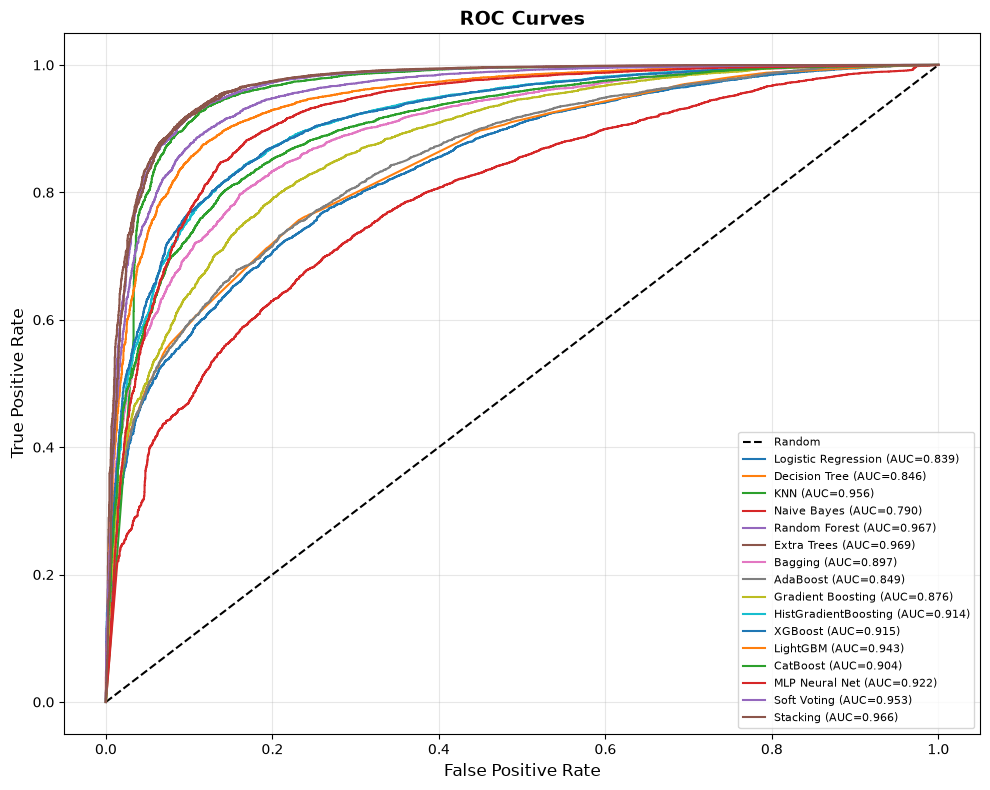

In [24]:
model_map = {
    'Logistic Regression': pipe_lr,
    'Decision Tree': pipe_dt,
    'KNN': pipe_knn,
    'Naive Bayes': pipe_nb,
    'Random Forest': pipe_rf,
    'Extra Trees': pipe_et,
    'Bagging': pipe_bag,
    'AdaBoost': pipe_ada,
    'Gradient Boosting': pipe_gb,
    'HistGradientBoosting': pipe_hgb,
    'XGBoost': pipe_xgb,
    'LightGBM': pipe_lgbm,
    'CatBoost': pipe_cat,
    'MLP Neural Net': pipe_mlp,
    'Soft Voting': pipe_vote,
    'Stacking': pipe_stack,
}

fig, ax = plt.subplots(figsize=(10, 8))
ax.plot([0, 1], [0, 1], 'k--', label='Random')

for name, model in model_map.items():
    fpr, tpr, _ = sm.roc_curve(y_test, positive_proba(model, X_test))
    ax.plot(fpr, tpr, label=f"{name} (AUC={results[name]['Test AUC']:.3f})")

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('house_models/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Load the Best Model

The model with the highest test AUC is loaded from disk. Change `best_name` to load a different one.

In [25]:
print("Saved models:")
for f in sorted(glob.glob('house_models/*.pkl')):
    print(f"  {f}")

best_name = df_results['Test AUC'].idxmax()
best_model = joblib.load(model_path(best_name))
print(f"\nLoaded: {best_name}")

Saved models:
  house_models/AdaBoost.pkl
  house_models/Bagging.pkl
  house_models/CatBoost.pkl
  house_models/Decision_Tree.pkl
  house_models/Extra_Trees.pkl
  house_models/Gradient_Boosting.pkl
  house_models/HistGradientBoosting.pkl
  house_models/KNN.pkl
  house_models/LightGBM.pkl
  house_models/Logistic_Regression.pkl
  house_models/MLP_Neural_Net.pkl
  house_models/Naive_Bayes.pkl
  house_models/Random_Forest.pkl
  house_models/Soft_Voting.pkl
  house_models/Stacking.pkl
  house_models/XGBoost.pkl

Loaded: Extra Trees


## 9. Predict a Single Listing

Edit the values below and run the cell to predict whether the property has a deed (Çıxarış):
1 = var (has a deed), 0 = yoxdur (no deed).

In [26]:
user_input = {
    'price': 85000,               # AZN
    'unit_price': 1200,           # AZN per m2
    'lat': 40.4093,
    'lng': 49.8671,
    'Sahə': 70,                   # area, m2
    'Mərtəbə': 5,                 # floor
    'Otaq sayı': 3,               # rooms
    'city': 'Bakı',
    'Kateqoriya': 'Köhnə tikili',
    'products_label': 'Satılır',
    'Təmir': 'Təmirsiz',
    'location': 'Nərimanov',
    'shop_name': 'Unknown',
}

df_user = add_house_features(pd.DataFrame([user_input]))

prediction = int(best_model.predict(df_user)[0])
proba_var = float(positive_proba(best_model, df_user)[0])
confidence = proba_var if prediction == POS_LABEL else 1 - proba_var

print(f"Prediction:   {TARGET_LABELS[prediction]}")
print(f"Confidence:   {confidence * 100:.1f}%")
print(f"P(var):       {proba_var * 100:.1f}%")
print(f"P(yoxdur):    {(1 - proba_var) * 100:.1f}%")

Prediction:   var
Confidence:   98.0%
P(var):       98.0%
P(yoxdur):    2.0%


## 10. Batch Prediction from CSV

Set `new_csv_path` to a CSV with the same columns as the training data and uncomment the code.

In [27]:
# new_csv_path = 'new_houses.csv'
# df_new = add_house_features(pd.read_csv(new_csv_path))
# df_new.replace([np.inf, -np.inf], np.nan, inplace=True)
# df_new['Predicted_Cixarish'] = best_model.predict(df_new)
# df_new['Probability_var'] = positive_proba(best_model, df_new).round(4)
# df_new.to_csv('predictions_output.csv', index=False)
# display(df_new[['Predicted_Cixarish', 'Probability_var']].head(10))